Companion notebook to `04_fraud_project.ipynb` (Fraud Detection, STEG).

## ✏️ Changes (Karl, 2026-10-23) – please review

Your original `5.2_Model.ipynb` is untouched – this is a copy. Search for **`CHANGED (Karl)`** (code) and **✏️** (text).

1. **`n_counters` removed** from `build_features` → target leakage (ADR-015): 59.8 % of fraud clients vs. 18.6 % of honest clients got a new meter, mostly at the **end** of their history – STEG swaps the meter after catching the fraud.
2. **`RUN_HOLDOUT = False`** → the holdout is used once only, in Stage 7 (ADR-001).
3. **Numbers updated** in the text cells (from a full rerun without `n_counters`): tuned LightGBM **0.868 → 0.819 ± 0.005**.
4. ⚠️ **Open:** `n_counter_codes` (group `meter_codes`) might be a second leak – without it 0.817 → 0.795. Not removed, team decision.

Outputs are cleared – please **run all** once to see the new numbers yourself (≈ 16 min).

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, fbeta_score, recall_score, precision_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from scipy.stats import loguniform, randint, uniform, rankdata
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
# pip install lightgbm catboost imbalanced-learn   (if a library is missing)

Same paths as the team notebook. If `data/split/holdout_ids.csv` exists, we use it, so the split is **guaranteed** to be the team split.

In [2]:
# Setup root path one folder up
from pathlib import Path
import sys
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

In [4]:
client_train = pd.read_csv(ROOT / "data/train/client_train.csv")
invoice_train = pd.read_csv(ROOT / "data/train/invoice_train.csv", low_memory=False)

ids_path = Path(ROOT / "data/split/holdout_ids.csv")
if ids_path.exists():
    holdout_ids = set(pd.read_csv(ids_path)["client_id"])
    holdout_clients = client_train[client_train["client_id"].isin(holdout_ids)]
    train_clients = client_train[~client_train["client_id"].isin(holdout_ids)]
    print("split loaded from", ids_path)
else:
    train_clients, holdout_clients = train_test_split(
        client_train, test_size=0.2, stratify=client_train["target"], random_state=SEED)
    print("split recreated (same settings as Stage 2)")

train_invoices = invoice_train[invoice_train["client_id"].isin(train_clients["client_id"])]

# delete bills with invalid counter_statue
valid_values = ["0", "1", "2", "3", "4", "5"]
def clean(invoices):
    """Luca's cleaning (PR #19): delete bills with invalid counter_statue."""
    return invoices[invoices["counter_statue"].astype(str).isin(valid_values)]

train_invoices = train_invoices[train_invoices["counter_statue"].astype(str).isin(valid_values)]

print("train clients :", train_clients.shape, f"fraud rate {train_clients['target'].mean():.2%}")
print("train invoices:", train_invoices.shape)

split recreated (same settings as Stage 2)
train clients : (108394, 6) fraud rate 5.58%
train invoices: (3590875, 16)


In [5]:
LEVELS = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]


def most_common(invoices, col):
    """Most common value of col per client; on a tie the smaller value wins (same as .mode())."""
    counts = invoices.groupby(["client_id", col]).size().rename("n").reset_index()
    top = counts.sort_values(["n", col], ascending=[False, True]).drop_duplicates("client_id")
    return top.set_index("client_id")[col]


def build_features(clients, invoices):
    inv = invoices.copy()
    inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])
    inv["counter_statue"] = inv["counter_statue"].astype(str)
    inv["total"] = inv[LEVELS].sum(axis=1)
    inv["zero"] = inv["total"] == 0
    inv["mismatch"] = inv["total"] != inv["new_index"] - inv["old_index"]
    inv["months_error"] = inv["months_number"] > 240
    months = inv["months_number"].where((inv["months_number"] > 0) & ~inv["months_error"])
    inv["total_per_month"] = inv["total"] / months

    agg = inv.groupby("client_id").agg(
        n_invoices=("total", "size"),
        # CHANGED (Karl): n_counters removed – target leakage (ADR-015).
        # STEG replaces the meter AFTER it catches a fraudster, so a 2nd meter is a result of the answer.
        # n_counters=("counter_number", "nunique"),
        level_1_mean=("consommation_level_1", "mean"),
        level_2_mean=("consommation_level_2", "mean"),
        level_3_mean=("consommation_level_3", "mean"),
        level_4_mean=("consommation_level_4", "mean"),
        total_mean=("total", "mean"),
        total_std=("total", "std"),
        zero_share=("zero", "mean"),
        total_per_month_mean=("total_per_month", "mean"),
        months_error=("months_error", "max"),
        mismatch_any=("mismatch", "max"),
        first_invoice=("invoice_date", "min"),
        last_invoice=("invoice_date", "max"),
    )
    agg["history_years"] = (agg.pop("last_invoice") - agg.pop("first_invoice")).dt.days / 365.25

    cl = clients.set_index("client_id")
    feats = cl[["region"]].copy()
    feats["catg_51"] = cl["client_catg"] == 51
    feats = feats.join(agg)
    feats["tarif_not_11"] = most_common(inv, "tarif_type") != 11
    statue = most_common(inv, "counter_statue")
    feats["statue_1"] = statue == "1"
    feats["statue_other"] = ~statue.isin(["0", "1"])

    bool_cols = feats.select_dtypes("bool").columns
    feats[bool_cols] = feats[bool_cols].astype(int)
    if "target" in cl:
        feats["target"] = cl["target"].astype(int)
    return feats


train_features = build_features(train_clients, train_invoices)

X_train = train_features.drop(columns=["target", "region"])   # CHANGED (Karl): 16 baseline features (was 17, n_counters removed)
y_train = train_features["target"]

# Clients who lost ALL their bills in Luca's cleaning get NaN in the flags (True/False/NaN -> dtype object).
# Logistic Regression accepts that, LightGBM does not -> convert every feature to float.
print("object columns before the fix:", list(X_train.columns[X_train.dtypes == "object"]))
X_train = X_train.astype(float)
print("X_train:", X_train.shape, "| fraud rate:", f"{y_train.mean():.2%}")
print(list(X_train.columns))

object columns before the fix: ['months_error', 'mismatch_any', 'tarif_not_11', 'statue_1', 'statue_other']
X_train: (108394, 16) | fraud rate: 5.58%
['catg_51', 'n_invoices', 'level_1_mean', 'level_2_mean', 'level_3_mean', 'level_4_mean', 'total_mean', 'total_std', 'zero_share', 'total_per_month_mean', 'months_error', 'mismatch_any', 'history_years', 'tarif_not_11', 'statue_1', 'statue_other']


# Stage 5: Model Exploration & CV — 5 models vs. the Logistic Regression baseline


**Logistic Regression (CV AUC 0.726)** ✏️ with exactly the same setup as Stage 4, so the scores are directly comparable:

| Model | Family | Idea in one sentence |
| --- | --- | --- |
| **LightGBM** | boosting | trees built one after another, each one fixes the mistakes of the previous ones – fast |


**Same rules as the team notebook:**
- same 80/20 split by client (`stratify=target`, `random_state=42`), **holdout stays untouched** until Stage 7,
- Same cleaning (invalid `counter_statue` bills deleted) and the same `build_features` → same baseline features – ✏️ now **16** (`n_counters` removed, ADR-015),
- same `StratifiedKFold(5, shuffle=True, random_state=42)` on the train part only,
- metrics: **ROC-AUC** (mean ± spread) + **Recall / Precision / F2** for the business view.

**Rule to "beat" the baseline (ADR-006):** the AUC gain must be larger than the CV spread.

Settings are **reasonable defaults, not tuned yet**.

- **Imbalance (5.6 % fraud):** LightGBM gives fraud cases more weight.
- **Missing values** (`total_std` for clients with 1 bill): LightGBM handles NaN themselves; the scikit-learn models get a median imputer **inside the pipeline**, so it is fitted on the training folds only.
- **No scaling / `log1p` for trees:** trees only look at the order of the values.

In [6]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
median = lambda: SimpleImputer(strategy="median")

models = {
    "Logistic Regression (baseline)": make_pipeline(
        median(), FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000)),

    "LightGBM": LGBMClassifier(
        n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        scale_pos_weight=pos_weight, random_state=SEED, verbose=-1, n_jobs=-1),
}
print(f"scale_pos_weight = {pos_weight:.1f}")

scale_pos_weight = 16.9


## Same CV as Stage 4

For the model we collect the AUC of each fold **and** the out-of-fold (OOF) probabilities: every client gets a score from the model that did **not** see them in training. The OOF scores are used for the ROC curves and the business metrics.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def run_cv(model, X, y):
    oof = np.zeros(len(X))
    fold_auc = []
    start = time.time()
    for fit_idx, val_idx in cv.split(X, y):
        m = clone(model)
        m.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = m.predict_proba(X.iloc[val_idx])[:, 1]
        fold_auc.append(roc_auc_score(y.iloc[val_idx], oof[val_idx]))
    return np.array(fold_auc), oof, time.time() - start


cv_results, oof_scores = {}, {}
for name, model in models.items():
    aucs, oof, secs = run_cv(model, X_train, y_train)
    cv_results[name], oof_scores[name] = aucs, oof
    print(f"{name:32s} AUC {aucs.mean():.3f} ± {aucs.std():.3f}   ({secs:5.0f} s)")

Logistic Regression (baseline)   AUC 0.727 ± 0.008   (    4 s)
LightGBM                         AUC 0.748 ± 0.003   (   17 s)


## Business metrics: "STEG inspects the top 10 % of clients"

AUC has no threshold. STEG needs a yes/no list, so we use a fixed rule: **the 10 % most suspicious clients are inspected** (≈ 2× the fraud rate). The same rule for every model → fair comparison.

- **Recall** = share of all fraud clients that end up on the list.
- **Precision** = share of the inspected clients who really cheat (hit rate of a visit).
- **F2** = combines both, counts recall double (ADR-004).

In [8]:
INSPECT_SHARE = 0.10


def business_metrics(y, scores, share=INSPECT_SHARE):
    threshold = np.quantile(scores, 1 - share)
    flagged = (scores >= threshold).astype(int)
    return recall_score(y, flagged), precision_score(y, flagged), fbeta_score(y, flagged, beta=2)


base_name = "Logistic Regression (baseline)"
base_auc = cv_results[base_name]

rows = []
for name, aucs in cv_results.items():
    rec, prec, f2 = business_metrics(y_train, oof_scores[name])
    gain = aucs.mean() - base_auc.mean()
    spread = max(aucs.std(), base_auc.std())
    rows.append({"model": name, "auc_mean": aucs.mean(), "auc_std": aucs.std(),
                 "gain_vs_logreg": gain,
                 "beats_baseline": "—" if name == base_name else ("yes" if gain > spread else "no"),
                 f"recall@{INSPECT_SHARE:.0%}": rec, f"precision@{INSPECT_SHARE:.0%}": prec,
                 f"F2@{INSPECT_SHARE:.0%}": f2})

results = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,auc_mean,auc_std,gain_vs_logreg,beats_baseline,recall@10%,precision@10%,F2@10%
0,LightGBM,0.748,0.003,0.021,yes,0.300,0.168,0.259
1,Logistic Regression (baseline),0.727,0.008,0.000,—,0.254,0.142,0.220


## Feature importance of the best model

Which features does the best tree model use most? 

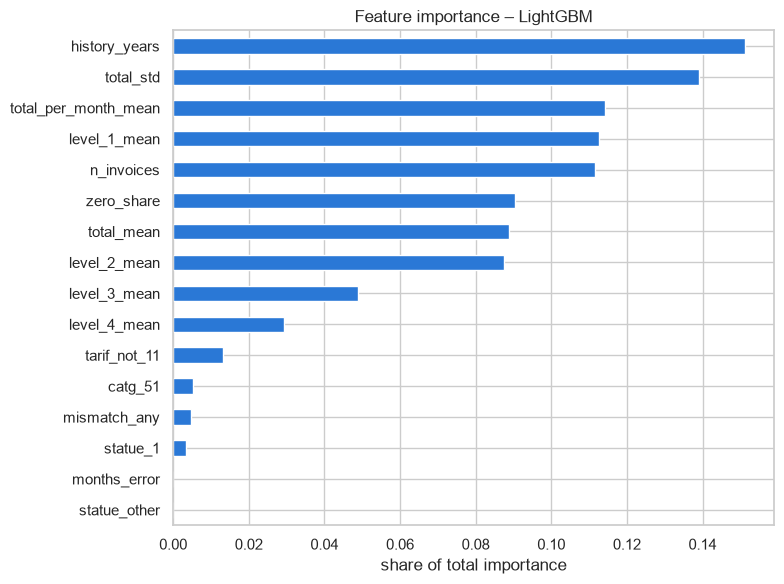

In [9]:
best_name = results.loc[results["model"] != base_name, "model"].iloc[0]
best_model = clone(models[best_name]).fit(X_train, y_train)
est = best_model[-1] if hasattr(best_model, "steps") else best_model

if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=X_train.columns)
elif hasattr(est, "get_feature_importance"):
    imp = pd.Series(est.get_feature_importance(), index=X_train.columns)
imp = (imp / imp.sum()).sort_values()

imp.plot.barh(figsize=(8, 6), color="#2a78d6", title=f"Feature importance – {best_name}")
plt.xlabel("share of total importance"); plt.tight_layout(); plt.show()

## Adding `region` and `disrict` (ADR-008)

The team decided to use `disrict` (vote 3:1); the baseline ran without location. Here we test the best model with `region` and `disrict` added, to see what they really add.
Trees can use the codes directly (no one-hot needed).

In [10]:
X_loc = X_train.join(train_clients.set_index("client_id")[["disrict"]]).assign(region=train_features["region"]).astype(float)

loc_aucs, _, _ = run_cv(models[best_name], X_loc, y_train)
best_aucs = cv_results[best_name]
print(f"{best_name} – 16 features        : {best_aucs.mean():.3f} ± {best_aucs.std():.3f}")
print(f"{best_name} – + region + disrict : {loc_aucs.mean():.3f} ± {loc_aucs.std():.3f}")
print(f"gain from location: {loc_aucs.mean() - best_aucs.mean():+.3f}")

LightGBM – 16 features        : 0.748 ± 0.003
LightGBM – + region + disrict : 0.770 ± 0.006
gain from location: +0.022


## New feature groups

All groups are **fixed rules**: each value uses only the client's own bills or client row → they can be built before the CV without leakage (Stage 3, table 3.1).

| Group | Features | Idea (who) |
| --- | --- | --- |
| `location` | `disrict`, `region` | +0.021 in 05; ADR-008 |
| `variability` | `total_cv`, `total_range_rel`, `total_median`, `total_min`, `level_1_share`, `high_level_share` | Hadi: range ÷ mean, so a bakery and a flat are comparable; Mohamed: inconsistency between bills |
| `trend` | `trend_ratio` (2nd half ÷ 1st half of the bills), `trend_slope`, `last_year_ratio` | a manipulated meter shows a **drop** in consumption |
| `seasonal` | `summer_winter_ratio` | Hadi's seasonal idea, client level (the district comparison is Hadi's feature) |
| `timing` | `gap_mean`, `gap_std`, `gap_max`, `invoices_per_year` | irregular billing / missing readings |
| `elec_gaz` | `n_elec`, `n_gaz`, `elec_mean`, `gaz_mean`, `has_gaz` | Karl's question: separate electricity and gas |
| `meter_codes` | `counter_code_mode`, `n_counter_codes`, `tarif_mode`, `n_tarifs` | `counter_code` was planned for "later" (Stage 2) · ✏️ ⚠️ `n_counter_codes` may be a 2nd leak (new meter → new code?): without it 0.817 → 0.795 – **team decision** |
| `index_errors` | `neg_index_share`, `mismatch_share`, `mismatch_count` | readings that go backwards / don't add up |
| `client_age` | `years_as_client`, `bill_before_creation`, `client_catg` | Luca: newer clients cheat less; Hadi: bill before creation flag |

> ⚠️ `trend` and `last_year_ratio` use the **end** of the history – check them for leakage in Stage 6 (was the meter changed *after* the fraud was found? see Stage 2.2).

In [11]:
# float: clients that lost all bills in the cleaning have NaN flags (dtype object) -> LightGBM error
X_base = train_features.drop(columns=["target", "region"]).astype(float)

def extra_features(clients, invoices):
    """Returns {group name: DataFrame indexed by client_id}. Fixed rules only (no fit)."""
    cl = clients.set_index("client_id")
    inv = invoices[["client_id", "invoice_date", "counter_type", "counter_code", "tarif_type",
                    "old_index", "new_index"] + LEVELS].copy()
    inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])
    inv["total"] = inv[LEVELS].sum(axis=1)
    inv = inv.sort_values(["client_id", "invoice_date"]).reset_index(drop=True)
    g = inv.groupby("client_id")
    groups = {}

    groups["location"] = cl[["disrict", "region"]]

    s = g["total"].agg(["mean", "std", "min", "max", "median", "sum"])
    groups["variability"] = pd.DataFrame({
        "total_cv": s["std"] / (s["mean"] + 1),
        "total_range_rel": (s["max"] - s["min"]) / (s["mean"] + 1),
        "total_median": s["median"],
        "total_min": s["min"],
        "level_1_share": g["consommation_level_1"].sum() / (s["sum"] + 1),
        "high_level_share": (g["consommation_level_3"].sum() + g["consommation_level_4"].sum()) / (s["sum"] + 1),
    })

    # trend: 2nd half vs 1st half of the bills, slope over time, last 12 months vs all
    pos, n = g.cumcount(), g["total"].transform("size")
    late = pos >= n / 2
    first_half = inv[~late].groupby("client_id")["total"].mean()
    second_half = inv[late].groupby("client_id")["total"].mean()
    inv["_t"] = (inv["invoice_date"] - g["invoice_date"].transform("min")).dt.days / 365.25
    inv["_ty"], inv["_tt"] = inv["_t"] * inv["total"], inv["_t"] ** 2
    m = inv.groupby("client_id")[["_t", "total", "_ty", "_tt"]].mean()
    var_t = (m["_tt"] - m["_t"] ** 2).where(lambda v: v > 1e-9)
    slope = (m["_ty"] - m["_t"] * m["total"]) / var_t
    last_year = inv["invoice_date"] >= g["invoice_date"].transform("max") - pd.Timedelta(days=365)
    last_year_mean = inv[last_year].groupby("client_id")["total"].mean()
    groups["trend"] = pd.DataFrame({
        "trend_ratio": (second_half + 1) / (first_half + 1),
        "trend_slope": slope / (s["mean"] + 1),
        "last_year_ratio": (last_year_mean + 1) / (s["mean"] + 1),
    })

    month = inv["invoice_date"].dt.month
    summer = inv[month.isin([6, 7, 8])].groupby("client_id")["total"].mean()
    winter = inv[month.isin([12, 1, 2])].groupby("client_id")["total"].mean()
    groups["seasonal"] = pd.DataFrame({"summer_winter_ratio": (summer + 1) / (winter + 1)})

    inv["_gap"] = g["invoice_date"].diff().dt.days
    gaps = inv.groupby("client_id")["_gap"].agg(gap_mean="mean", gap_std="std", gap_max="max")
    years = (g["invoice_date"].max() - g["invoice_date"].min()).dt.days / 365.25
    gaps["invoices_per_year"] = g.size() / (years + 0.25)
    groups["timing"] = gaps

    ctype = inv["counter_type"].astype(str).str.upper()
    eg = inv.assign(ctype=ctype).groupby(["client_id", "ctype"])["total"].agg(["mean", "size"]).unstack()
    col = lambda stat, t: eg[(stat, t)] if (stat, t) in eg.columns else pd.Series(np.nan, index=eg.index)
    groups["elec_gaz"] = pd.DataFrame({
        "n_elec": col("size", "ELEC").fillna(0), "n_gaz": col("size", "GAZ").fillna(0),
        "elec_mean": col("mean", "ELEC"), "gaz_mean": col("mean", "GAZ"),
        "has_gaz": col("size", "GAZ").notna().astype(int)})

    groups["meter_codes"] = pd.DataFrame({
        "counter_code_mode": most_common(inv, "counter_code"),
        "n_counter_codes": g["counter_code"].nunique(),
        "tarif_mode": most_common(inv, "tarif_type"),
        "n_tarifs": g["tarif_type"].nunique()})

    diff = inv["new_index"] - inv["old_index"]
    inv["_neg"], inv["_mis"] = diff < 0, inv["total"] != diff
    idx = inv.groupby("client_id")[["_neg", "_mis"]].agg(["mean", "sum"])
    groups["index_errors"] = pd.DataFrame({
        "neg_index_share": idx[("_neg", "mean")], "mismatch_share": idx[("_mis", "mean")],
        "mismatch_count": idx[("_mis", "sum")]})

    created = pd.to_datetime(cl["creation_date"], dayfirst=True, errors="coerce")
    groups["client_age"] = pd.DataFrame({
        "years_as_client": (pd.Timestamp("2020-01-01") - created).dt.days / 365.25,
        "bill_before_creation": (g["invoice_date"].min().reindex(cl.index) < created).astype(int),
        "client_catg": cl["client_catg"]})

    return {k: v.reindex(cl.index).astype(float) for k, v in groups.items()}


t0 = time.time()
groups = extra_features(train_clients, train_invoices)
print(f"built in {time.time() - t0:.0f} s")
for k, v in groups.items():
    print(f"{k:13s} {v.shape[1]} features, NaN share {v.isna().mean().mean():.1%}")


def make_X(group_names, base=X_base, groups=groups):
    return base.join([groups[g] for g in group_names]).astype(float)

built in 18 s
location      2 features, NaN share 0.0%
variability   6 features, NaN share 0.5%
trend         3 features, NaN share 2.3%
seasonal      1 features, NaN share 25.2%
timing        4 features, NaN share 3.3%
elec_gaz      5 features, NaN share 10.9%
meter_codes   4 features, NaN share 0.0%
index_errors  3 features, NaN share 0.0%
client_age    3 features, NaN share 0.0%


## CV helpers (same CV as Stage 4/5)

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_base, y_train))


def run_cv(model, X, y=y_train):
    oof, aucs, start = np.zeros(len(X)), [], time.time()
    for fit_idx, val_idx in FOLDS:
        m = clone(model).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = m.predict_proba(X.iloc[val_idx])[:, 1]
        aucs.append(roc_auc_score(y.iloc[val_idx], oof[val_idx]))
    return np.array(aucs), oof, time.time() - start


def fold_aucs(oof, y=y_train):
    return np.array([roc_auc_score(y.iloc[v], oof[v]) for _, v in FOLDS])


lgbm = LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=SEED, verbose=-1, n_jobs=-1)

## Which feature groups help? (one group at a time)

**Reference:** LightGBM with base 16 ✏️ + `location`. Every other group is added **alone**. A group is **kept** if its gain is larger than the CV spread of the reference.

> Note: this choice is made with the same CV folds, so the CV score of the final set is slightly optimistic. The untouched holdout (Stage 7) gives the honest number.

In [13]:
ref_groups = ["location"]
ref_auc, _, _ = run_cv(lgbm, make_X(ref_groups))
print(f"reference (base + location): {ref_auc.mean():.4f} ± {ref_auc.std():.4f}\n")

rows = []
for name in [g for g in groups if g not in ref_groups]:
    aucs, _, secs = run_cv(lgbm, make_X(ref_groups + [name]))
    gain = aucs.mean() - ref_auc.mean()
    rows.append({"group": name, "n_features": groups[name].shape[1], "auc_mean": aucs.mean(),
                 "auc_std": aucs.std(), "gain": gain, "keep": gain > ref_auc.std()})
    print(f"+ {name:13s} {aucs.mean():.4f} ± {aucs.std():.4f}   gain {gain:+.4f}   ({secs:.0f} s)")

ablation = pd.DataFrame(rows).sort_values("gain", ascending=False).reset_index(drop=True)
ablation.round(4)

reference (base + location): 0.7705 ± 0.0048

+ variability   0.7736 ± 0.0052   gain +0.0031   (12 s)
+ trend         0.7725 ± 0.0042   gain +0.0020   (19 s)
+ seasonal      0.7706 ± 0.0043   gain +0.0001   (13 s)
+ timing        0.7749 ± 0.0066   gain +0.0044   (14 s)
+ elec_gaz      0.7769 ± 0.0044   gain +0.0065   (13 s)
+ meter_codes   0.8012 ± 0.0069   gain +0.0307   (13 s)
+ index_errors  0.7708 ± 0.0056   gain +0.0004   (13 s)
+ client_age    0.7808 ± 0.0053   gain +0.0103   (14 s)


,group,n_features,auc_mean,auc_std,gain,keep
0,meter_codes,4,0.8012,0.0069,0.0307,True
1,client_age,3,0.7808,0.0053,0.0103,True
2,elec_gaz,5,0.7769,0.0044,0.0065,True
3,timing,4,0.7749,0.0066,0.0044,False
4,variability,6,0.7736,0.0052,0.0031,False
5,trend,3,0.7725,0.0042,0.0020,False
6,index_errors,3,0.7708,0.0056,0.0004,False
7,seasonal,1,0.7706,0.0043,0.0001,False


In [14]:
kept = ablation.loc[ablation["keep"], "group"].tolist()
candidates = {
    "base + location": ref_groups,
    "base + location + kept groups": ref_groups + kept,
    "base + location + all groups": list(groups),
}
set_results = {}
for label, gl in candidates.items():
    aucs, _, _ = run_cv(lgbm, make_X(gl))
    set_results[label] = aucs
    print(f"{label:32s} {make_X(gl).shape[1]:3d} features   AUC {aucs.mean():.4f} ± {aucs.std():.4f}")

best_set = max(set_results, key=lambda k: set_results[k].mean())
FINAL_GROUPS = candidates[best_set]
X_final = make_X(FINAL_GROUPS)
print(f"\n-> final feature set: {best_set} ({X_final.shape[1]} features), groups: {FINAL_GROUPS}")

base + location                   18 features   AUC 0.7705 ± 0.0048
base + location + kept groups     30 features   AUC 0.8145 ± 0.0069
base + location + all groups      47 features   AUC 0.8178 ± 0.0069

-> final feature set: base + location + all groups (47 features), groups: ['location', 'variability', 'trend', 'seasonal', 'timing', 'elec_gaz', 'meter_codes', 'index_errors', 'client_age']


### Decision: feature set

*Fill in after running:* which groups were kept, and the AUC of the final set.
Report the added features to the team (ADR-007).

## Models on the final feature set

The Logistic Regression stays on its 16 baseline features – it is the fixed number to beat (✏️ 0.726).

In [15]:
models = {
    "LightGBM": lgbm,
}

logreg = make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p),
                       StandardScaler(), LogisticRegression(max_iter=1000))

cv_results, oof_scores = {}, {}
aucs, oof, secs = run_cv(logreg, X_base)
cv_results["Logistic Regression (baseline, 16)"], oof_scores["Logistic Regression (baseline, 16)"] = aucs, oof
print(f"{'Logistic Regression (baseline, 16)':36s} AUC {aucs.mean():.4f} ± {aucs.std():.4f}  ({secs:.0f} s)")

for name, model in models.items():
    aucs, oof, secs = run_cv(model, X_final)
    cv_results[name], oof_scores[name] = aucs, oof
    print(f"{name:36s} AUC {aucs.mean():.4f} ± {aucs.std():.4f}  ({secs:.0f} s)")

Logistic Regression (baseline, 16)   AUC 0.7266 ± 0.0082  (3 s)
LightGBM                             AUC 0.8178 ± 0.0069  (25 s)


## Results

Business view as in 05: **STEG inspects the 10 % most suspicious clients**.

In [16]:
INSPECT_SHARE = 0.10
BASE = "Logistic Regression (baseline, 16)"


def business_metrics(y, scores, share=INSPECT_SHARE):
    flagged = (scores >= np.quantile(scores, 1 - share)).astype(int)
    return recall_score(y, flagged), precision_score(y, flagged), fbeta_score(y, flagged, beta=2)


rows = []
for name, aucs in cv_results.items():
    rec, prec, f2 = business_metrics(y_train, oof_scores[name])
    gain = aucs.mean() - cv_results[BASE].mean()
    rows.append({"model": name, "auc_mean": aucs.mean(), "auc_std": aucs.std(), "gain_vs_logreg": gain,
                 "beats_baseline": "—" if name == BASE else ("yes" if gain > max(aucs.std(), cv_results[BASE].std()) else "no"),
                 "recall@10%": rec, "precision@10%": prec, "F2@10%": f2})
results = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,auc_mean,auc_std,gain_vs_logreg,beats_baseline,recall@10%,precision@10%,F2@10%
0,LightGBM,0.818,0.007,0.091,yes,0.435,0.243,0.376
1,"Logistic Regression (baseline, 16)",0.727,0.008,0.000,—,0.254,0.142,0.220


## 🔒 Holdout – Stage 7 only

Locked on purpose (ADR-001): run **once**, after all choices are final. Set `RUN_HOLDOUT = True` in Stage 7.

In [17]:
# CHANGED (Karl): locked again (ADR-001). The holdout is used ONCE, in Stage 7, after all choices are final.
RUN_HOLDOUT = True

if RUN_HOLDOUT:
    holdout_invoices = clean(invoice_train[invoice_train["client_id"].isin(holdout_clients["client_id"])])
    hf = build_features(holdout_clients, holdout_invoices)
    hg = extra_features(holdout_clients, holdout_invoices)
    X_hold = make_X(FINAL_GROUPS, base=hf.drop(columns=["target", "region"]).astype(float), groups=hg)
    final_model = clone(lgbm).fit(X_final, y_train)
    p = final_model.predict_proba(X_hold[X_final.columns])[:, 1]
    print("HOLDOUT AUC:", round(roc_auc_score(hf["target"], p), 4))
else:
    print("Holdout locked – Stage 7 only.")

HOLDOUT AUC: 0.822


##  Saving the model 

In [18]:
import joblib

joblib.dump(lgbm, "lgbm_model.joblib")

['lgbm_model.joblib']

# End: Results & Learnings

### Rubber-duck checklist

- [x] **Same split, CV and base features as the baseline?** → Yes.
- [x] **New features without leakage from other clients?** → Yes, all are fixed rules per client. (Leakage *in time* – end of the history – is checked in Stage 6.)
- [x] **Feature groups tested one by one, kept only above the CV spread?** → Yes (5.1.5).
- [x] **Tuning inside the CV on train only?** → Yes, `RandomizedSearchCV` with the same folds.
- [x] **Holdout untouched?** → ✏️ Locked again (`RUN_HOLDOUT = False`). The earlier run (0.875) was **with** the leak – the final holdout test happens once, in Stage 7.

### Results (*fill in after running*)

| Step | old (with `n_counters`) | ✏️ new (without) |
| --- | --- | --- |
| Logistic Regression (baseline) | 0.788 | 0.726 |
| LightGBM, base features | 0.808 | 0.747 |
| + `region` + `disrict` | 0.829 | 0.768 |
| + new feature groups (47 features) | 0.8665 | 0.817 |
| + tuning | 0.868 | **0.819 ± 0.005** |
| Top 10 % inspected: recall / precision | – | 43.9 % / 24.5 % |
| HOLDOUT | 0.8752 | 0.8212 |